Simple Linear Regression

In [38]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import pylab as pl
%matplotlib inline

In [39]:
df = pd.read_csv("FuelConsumption.csv")

# take look at dataset
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [40]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [41]:
cdf = df[["CO2EMISSIONS" , "CYLINDERS" , "ENGINESIZE" , "FUELCONSUMPTION_COMB"]]

cdf.head(5)

,CO2EMISSIONS,CYLINDERS,ENGINESIZE,FUELCONSUMPTION_COMB
0,196,4,2.0,8.5
1,221,4,2.4,9.6
2,136,4,1.5,5.9
3,255,6,3.5,11.1
4,244,6,3.5,10.6


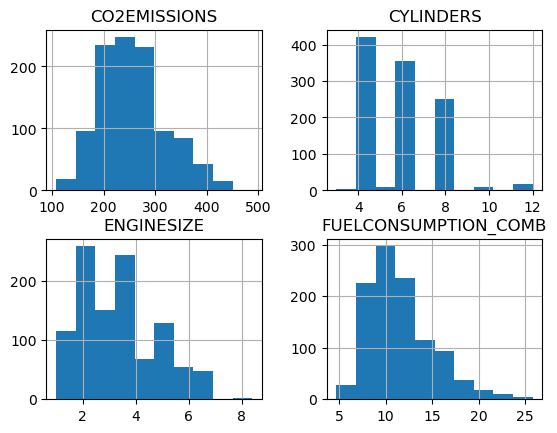

In [42]:
viz = cdf[["CO2EMISSIONS" , "CYLINDERS" , "ENGINESIZE" , "FUELCONSUMPTION_COMB"]]
viz.hist()
plt.show()

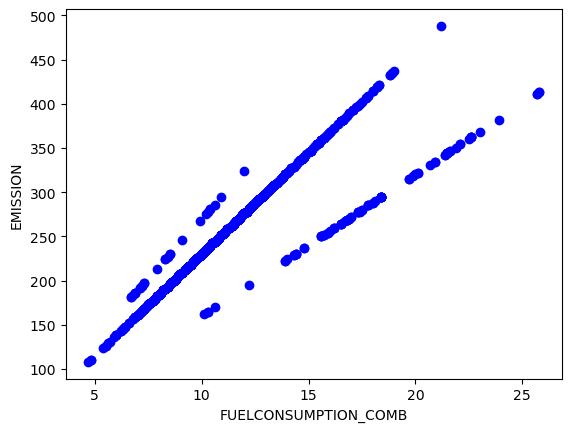

In [43]:
plt.scatter(cdf.FUELCONSUMPTION_COMB , cdf.CO2EMISSIONS, color= "blue")
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("EMISSION")
plt.show()

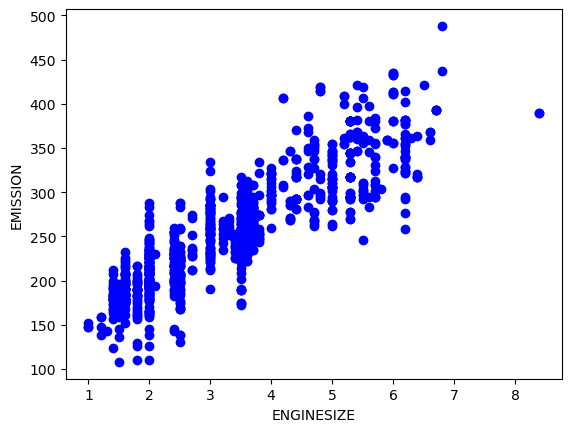

In [44]:
plt.scatter(cdf.ENGINESIZE , cdf.CO2EMISSIONS , color= "blue")
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSION")
plt.show()

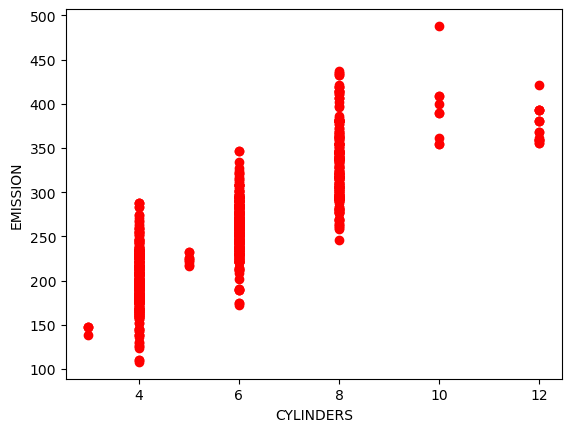

In [45]:
plt.scatter(cdf.CYLINDERS , cdf.CO2EMISSIONS , color ="red")
plt.xlabel("CYLINDERS")
plt.ylabel("EMISSION")
plt.show()

In [46]:
msk = np.random.rand(len(df)) < 0.8
train = cdf [msk]
test = cdf [~msk]

test

,CO2EMISSIONS,CYLINDERS,ENGINESIZE,FUELCONSUMPTION_COMB
1,221,4,2.4,9.6
3,255,6,3.5,11.1
4,244,6,3.5,10.6
6,232,6,3.5,10.1
7,255,6,3.7,11.1
...,...,...,...,...
1038,207,4,2.0,9.0
1047,248,6,3.6,10.8
1049,184,4,2.0,6.8
1058,264,6,3.0,11.5


In [47]:
from sklearn import linear_model
reg = linear_model.LinearRegression()
train_x = np.asanyarray(train[["ENGINESIZE"]])
train_y = np.asanyarray(train[["CO2EMISSIONS"]])

reg.fit(train_x , train_y)
print("Coefficients :" , reg.coef_ )
print("Intercept : " , reg.intercept_)

Coefficients : [[39.42184534]]
Intercept :  [125.20305483]


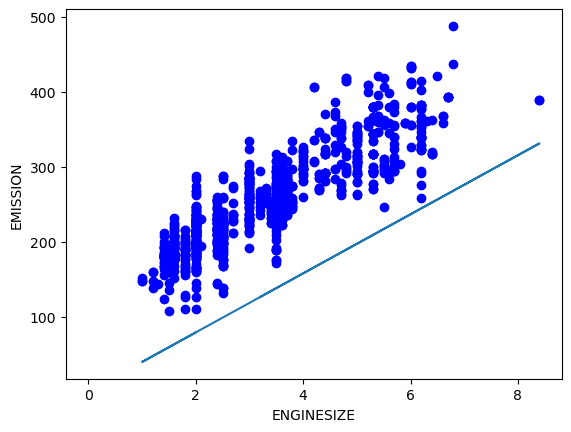

In [48]:
plt.scatter(cdf.ENGINESIZE , cdf.CO2EMISSIONS , color = "blue")
plt.plot(train_x , reg.coef_[0][0] * train_x , reg.intercept_[0] , '-r')
plt.xlabel("ENGINESIZE")
plt.ylabel("EMISSION")
plt.show()

In [49]:
from sklearn.metrics import r2_score
test_x = np.asanyarray(test[["ENGINESIZE"]])
test_y = np.asanyarray(test[["CO2EMISSIONS"]])
test_y_ = reg.predict(test_x)

print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y - test_y_)))

print("Residual sum of squares (MSE): %.2f" % np.mean((test_y - test_y_) **2))

print("R2-score: %.2f" % r2_score(test_y_ , test_y))


Mean absolute error: 20.66
Residual sum of squares (MSE): 745.68
R2-score: 0.75
